In [11]:
%pip install langchain_tavily
import os
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langgraph.graph.message import StateGraph
from langgraph.graph.state import START,END
from langchain_tavily import TavilySearch
from langgraph.prebuilt import tool_node,tools_condition

load_dotenv()

Note: you may need to restart the kernel to use updated packages.


True

In [13]:
llm=ChatGroq(model="openai/gpt-oss-20b")

from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages:Annotated[list,add_messages]


def addition(a:int,b:int):
    """
    This is a function that adds up two numbers.

    Args:
        a (int): The first number.
        b (int): The second number.

    Returns:
        int: The sum of a and b.
    """
    return a+b

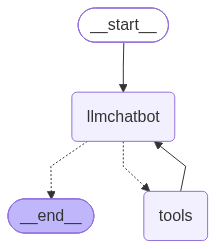

In [22]:
from langgraph.prebuilt import ToolNode

tool=TavilySearch(max_results=2)
tools=[tool,addition]

llm_with_tools=llm.bind_tools(tools)

def chatbot(state:State):
    return{"messages":[llm_with_tools.invoke(state["messages"])]}

graphbuilder=StateGraph(State)
#adding nodes
graphbuilder.add_node("llmchatbot",chatbot)
graphbuilder.add_node("tools",ToolNode(tools))

#adding edges
graphbuilder.add_edge(START,"llmchatbot")
graphbuilder.add_conditional_edges(
    "llmchatbot",
    tools_condition
)
graphbuilder.add_edge("tools","llmchatbot")

graph=graphbuilder.compile()


from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

In [20]:
response=graph.invoke({"messages":"What is the latest ecommerce news?"})

response["messages"][-1]

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the latest ecommerce news?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_31faf69a-b8b9-47e2-a81f-90e123999d69)
 Call ID: fc_31faf69a-b8b9-47e2-a81f-90e123999d69
  Args:
    query: latest ecommerce news
    search_depth: advanced
    time_range: day
    topic: general
================================= Tool Message =================================
Name: tavily_search

{"query": "latest ecommerce news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.businesswire.com/newsroom/industry/technology/ecommerce", "title": "Electronic Commerce Breaking News and Press Releases", "content": "#### Services & Solutions\n\n### Services\n\n### Solutions For\n\n#### Resources\n\n### Education\n\n### Why Business Wire\n\nExplore ways to use Business Wire features for your next news release\n\n# Electronic

In [23]:
response=graph.invoke({"messages":"What is 100 plus 66?"})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is 100 plus 66?
================================== Ai Message ==================================
Tool Calls:
  addition (fc_4d20b3f2-daa7-4f74-a0d3-edd084f32a2d)
 Call ID: fc_4d20b3f2-daa7-4f74-a0d3-edd084f32a2d
  Args:
    a: 100
    b: 66
================================= Tool Message =================================
Name: addition

166
================================== Ai Message ==================================

166


In [24]:
response=graph.invoke({"messages":"Give me the recent stock market news then add 1864 with 1796"})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me the recent stock market news then add 1864 with 1796
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_44a18d03-b93f-4191-af93-a937d2a41738)
 Call ID: fc_44a18d03-b93f-4191-af93-a937d2a41738
  Args:
    query: recent stock market news
    search_depth: basic
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent stock market news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.reuters.com/business/finance/fearless-us-stock-market-vulnerable-shocks-midterms-loom-2026-09-09", "title": "Fearless US stock market vulnerable to shocks as ...", "content": "NEW YORK, Sept 9 (Reuters) - With two months until the U.S. midterm elections, the options market is showing a potentially toxic mix of fragilit

In [25]:
response=graph.invoke({"messages":"what is 5 to the power of 3"})

for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

what is 5 to the power of 3
================================== Ai Message ==================================

5 to the power of 3 is **125**.
